# Introduction

The purpose of this notebook is to explore and evaluate a similarity-based nearest-neighbour approach for identifying existing Airbnb listings that are comparable to a hypothetical listing based on their characteristics.

In [66]:
import pandas as pd
import numpy as np
from postgre_tools import Users, create_postgres_engine
import matplotlib.pyplot as plt


In [ ]:
engine = create_postgres_engine(Users.AIRBNB.load_user())

# Set count to None if you want to fetch all rows
listings_row_count: int | None = None
amenities_row_count: int | None = None

if listings_row_count is not None and listings_row_count <= 0:
    raise ValueError("listings_row_count must be greater than 0")
if amenities_row_count is not None and amenities_row_count <= 0:
    raise ValueError("amenities_row_count must be greater than 0")

listings_query = "SELECT id, room_type, accommodates, bedrooms, beds, district FROM listings"
amenities_query = "SELECT * FROM listing_amenities"

if listings_row_count is not None:
    listings_query += f" LIMIT {listings_row_count}"

if amenities_row_count is not None:
    amenities_query += f" LIMIT {amenities_row_count}"

listings_df = pd.read_sql(listings_query, engine)
listing_amenities_df = pd.read_sql(amenities_query, engine)

engine.dispose()

In [16]:
print(f"Columns in listings_df: {listings_df.columns}")
print(f"\nData types in listings_df:\n{listings_df.dtypes}")
listings_df

Columns in listings_df: Index(['id', 'room_type', 'accommodates', 'bedrooms', 'beds', 'district'], dtype='str')

Data types in listings_df:
id                int64
room_type           str
accommodates      int64
bedrooms        float64
beds            float64
district            str
dtype: object


,id,room_type,accommodates,bedrooms,beds,district
0,145320,Private room,2,1.0,1.0,Södermalm
1,164448,Private room,2,NaN,2.0,Södermalm
2,220851,Private room,1,NaN,1.0,Kungsholmen
3,242188,Private room,1,NaN,1.0,Södermalm
4,273906,Entire home/apt,4,3.0,NaN,Södermalm
...,...,...,...,...,...,...
4801,1717861167246979973,Entire home/apt,2,1.0,1.0,Skarpnäck
4802,1718132464242032867,Private room,2,1.0,1.0,Järva
4803,1718263471917793029,Entire home/apt,2,1.0,1.0,Bromma
4804,1718288866708700915,Entire home/apt,2,1.0,1.0,Kungsholmen


All columns in `listings_df`, except `id`, are used as features for calculating similarity between listings. The `room_type` and `district` columns are categorical, and their differences are evaluated using exact matching (`==`). A match is assigned a distance of 0, while a mismatch is assigned a distance of 1. The numerical columns—`accommodates`, `bedrooms`, and `beds`—can be compared using Euclidean distance. However, normalization or standardization should be considered to ensure that differences in feature scales do not disproportionately influence the resulting similarity scores.


To address this, we will use a form of **robust scaling** based on the Interquartile Range (IQR). The IQR is defined as the difference between the 75th percentile (Q3) and the 25th percentile (Q1) of a feature's distribution. Unlike standard deviation, the IQR is less sensitive to extreme values, making it suitable for potentially skewed features such as guest capacity, bedrooms, and beds.

In [ ]:

CATEGORICAL_COLUMNS = ["room_type", "district"]
NUMERICAL_COLUMNS = ["accommodates", "bedrooms", "beds"]
listings_df[NUMERICAL_COLUMNS].describe().T

,count,mean,std,min,25%,50%,75%,max
accommodates,4806.0,3.602788,2.089303,1.0,2.0,3.0,5.0,16.0
bedrooms,4109.0,1.920662,1.227736,0.0,1.0,1.0,3.0,12.0
beds,2882.0,2.364330,1.834288,1.0,1.0,2.0,3.0,22.0


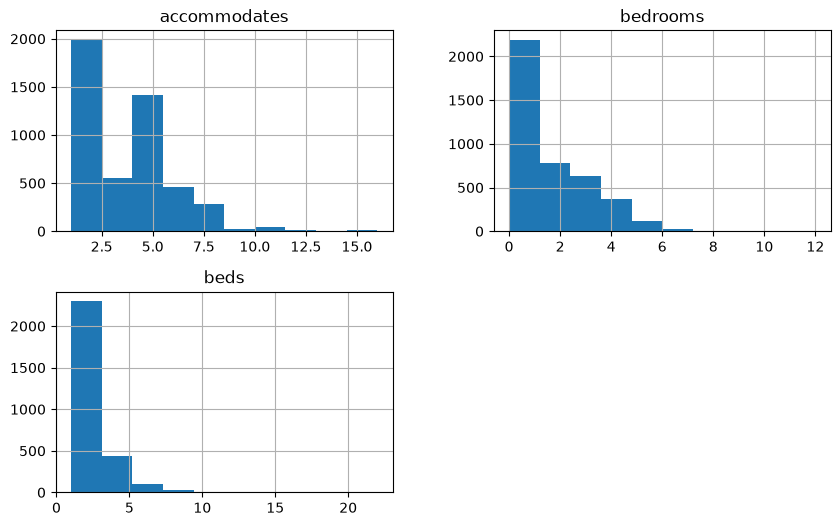

In [67]:
# Create a histogram of the numerical columns
listings_df[NUMERICAL_COLUMNS].hist(figsize=(10, 6))
plt.show()

As shown in the descriptive statistics above, the numerical features are concentrated within relatively small ranges. For instance, the middle 50% of listings accommodate between 2 and 5 guests, have between 1 and 3 bedrooms, and contain between 1 and 3 beds. However, the maximum values are considerably higher, reaching 16 guests, 12 bedrooms, and 22 beds. This suggests that the distributions may be right-skewed, which is further supported by the histograms, where most observations are concentrated at lower values, with relatively few observations extending into the higher ranges. Using IQR-based scaling allows us to normalize numerical differences relative to the spread of the central 50% of observations, reducing the influence of these extreme values on the scaling factors.

For each numerical feature, the absolute difference between the hypothetical listing and an existing listing will be divided by the feature's IQR:

$
d_j(h,x) = \frac{|h_j-x_j|}{IQR_j}
$

Here, $h_j$ and $x_j$ represent the feature values of the hypothetical and existing listings, respectively. The IQR is calculated from the corresponding feature across the existing listings in the dataset.

Since we are interested in the differences between individual listings, subtracting the median, as done in conventional robust scaling, is unnecessary because it would cancel out when calculating the distance. Dividing by the IQR expresses each difference relative to the feature's typical variation, making numerical differences more comparable across features.

Finally, the scaled numerical differences will be combined using Euclidean distance to obtain a numerical distance score between the listings. A smaller distance indicates greater similarity in their numerical characteristics.


### Final Distance Measure

The final distance measure combines the categorical distances with the Euclidean distance of the IQR-scaled numerical features:

$$
D(h,x) =
\underbrace{\sum_{j \in C} \mathbb{1}(h_j \neq x_j)}_{\text{Categorical distance}}
+
\underbrace{\sqrt{\sum_{j \in N}\left(\frac{h_j-x_j}{IQR_j}\right)^2}}_{\text{Numerical distance}}
$$

Where:
- $h$ represents the hypothetical listing.
- $x$ represents an existing listing.
- $C$ is the set of categorical features (`room_type`, `district`).
- $N$ is the set of numerical features (`accommodates`, `bedrooms`, `beds`).
- $\mathbb{1}(h_j \neq x_j)$ is an indicator function that equals 1 when the categorical values differ and 0 otherwise.
- $IQR_j$ is the interquartile range of numerical feature \(j\), calculated from the existing listings.

The resulting distance is a non-negative value, where **smaller distances indicate greater similarity** between listings. A distance of 0 indicates that the listings have identical values across all features used in the comparison.

In [30]:

HYPOTHETICAL_LISTING = {
    "room_type": "Private room",
    "accommodates": 4,
    "bedrooms": 2,
    "beds": 1,
    "district": "Södermalm"
}

In [68]:

def distance(hypo_listing: dict, listings: pd.DataFrame):
    """Calculate the distance between a hypothetical listing and a set of listings using the method described above."""
    distances = pd.Series(
        0.0, index=listings.index, dtype=float
    )

    # Categorical distances
    for category in CATEGORICAL_COLUMNS:
        if hypo_listing[category] is None:
            continue

        distances += (
            listings[category] != hypo_listing[category]
        ).astype(float)

    # Calculate IQR scales
    values = listings[NUMERICAL_COLUMNS].astype(float)
    numeric_scales = (
        values.quantile(0.75)
        - values.quantile(0.25)
    )

    # Convert hypothetical listing values to floats
    query_values = (
        pd.Series(hypo_listing)[NUMERICAL_COLUMNS]
        .astype(float)
    )

    # Calculate normalized differences
    differences = (
        values - query_values
    ) / numeric_scales.replace(0, 1.0)

    # Handle missing values
    differences = differences.abs().clip(upper=3.0).fillna(3.0)

    # Calculate Euclidean distances
    distances += np.sqrt(
        differences.pow(2).sum(axis=1)
    )

    return distances.sort_values()

distance(HYPOTHETICAL_LISTING, listings_df)[:10]

4315    0.500000
4421    0.600925
2719    0.781736
2353    0.781736
1142    0.781736
2351    0.833333
2352    0.833333
793     0.833333
2472    0.833333
1147    0.833333
dtype: float64

### Clipping Numerical Differences

To prevent unusually large differences in a single numerical feature from dominating the overall distance, we apply clipping to the IQR-scaled differences. Specifically, each normalized difference is limited to a maximum value of 3, meaning that differences exceeding three times the feature's IQR are treated equally.

This is particularly relevant given the right-skewed distributions of the numerical features, where a small number of listings have unusually large capacities, bedrooms, or beds. Since Euclidean distance involves squaring the normalized differences, extreme values could otherwise have a disproportionate influence on the final similarity score.

However, clipping introduces a trade-off: differences exceeding the threshold are no longer distinguishable. The threshold of 3 is therefore a heuristic choice intended to balance sensitivity to numerical differences with robustness against extreme values.

Additionally, missing numerical values are assigned a normalized difference of 3, treating them as a maximum-penalty mismatch.

In [32]:
listing_amenities_df

,listing_id,amenity
0,1000056802929658315,Bed linens
1,1000056802929658315,Body soap
2,1000056802929658315,Cleaning products
3,1000056802929658315,Coffee
4,1000056802929658315,Coffee maker
...,...,...
103358,999790679792070930,Outdoor dining area
103359,999790679792070930,Refrigerator
103360,999790679792070930,Smoke alarm
103361,999790679792070930,TV
